# PRIM — Ambulance Pooling Demand Patterns

Find the demand conditions where ambulance pooling helps vs hurts.
Inter-bn distance fixed at 35 min (Sobol ST=0.05, negligible).

Then for each PRIM dimension, pick a matched pair of scenarios
that differ on that dimension but are similar on everything else,
for replay and causal analysis.

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ema_workbench.analysis import prim

# ── CONFIGURATION ────────────────────────────────────────────────────────────
FOLDER_NAME = "20260605_162142_scenario_2btg_pooling_limit_baseline_amb"
OUTCOME = "death_rate_T1_BCAS"
BENEFIT_THRESHOLD = -0.1   # delta > this means pooling helped LITTLE
# ─────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(paths.MULTI_RUN_OUTPUT / FOLDER_NAME / "results.csv")
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]

base = df[df["ambulance_eligibility"] == 0].sort_values("scenario").reset_index(drop=True)
pool = df[df["ambulance_eligibility"] == 1].sort_values("scenario").reset_index(drop=True)
assert (base["scenario"].values == pool["scenario"].values).all()

merged = base[UNCERTAINTIES + [OUTCOME]].copy()
merged["mort_base"] = base[OUTCOME].values
merged["mort_pool"] = pool[OUTCOME].values
merged["delta"] = merged["mort_pool"] - merged["mort_base"]

print(f"Matched scenarios: {len(merged)}")
print(f"Delta range: {merged['delta'].min():.4f} to {merged['delta'].max():.4f}")
print(f"Median delta: {merged['delta'].median():.4f}")
print(f"Pooling helped little (delta > {BENEFIT_THRESHOLD}): {(merged['delta'] > BENEFIT_THRESHOLD).sum()} / {len(merged)} ({(merged['delta'] > BENEFIT_THRESHOLD).mean():.1%})")

C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\em_framework\__init__.py:101: UserWarning: ipyparallel not installed - IpyparalleEvaluator not available
  warnings.warn("ipyparallel not installed - IpyparalleEvaluator not available")


Loaded 2000 runs
Matched scenarios: 1000
Delta range: -1.0000 to 0.5000
Median delta: -0.4286
Pooling helped little (delta > -0.1): 103 / 1000 (10.3%)


## Distribution of Pooling Benefit

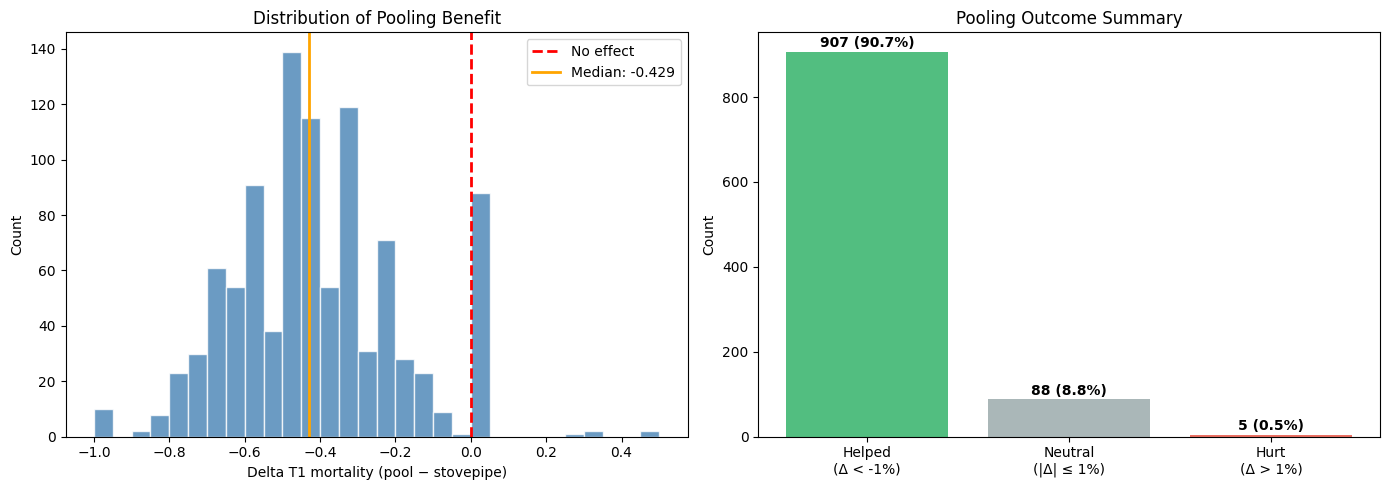

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(merged["delta"], bins=30, color="steelblue", alpha=0.8, edgecolor="white")
axes[0].axvline(0, color="red", linewidth=2, linestyle="--", label="No effect")
axes[0].axvline(merged["delta"].median(), color="orange", linewidth=2, linestyle="-", label=f"Median: {merged['delta'].median():.3f}")
axes[0].set_xlabel("Delta T1 mortality (pool − stovepipe)")
axes[0].set_ylabel("Count")
axes[0].set_title("Distribution of Pooling Benefit")
axes[0].legend()

# Stacked bar: helped vs no effect vs hurt
n_helped = (merged["delta"] < -0.01).sum()
n_neutral = ((merged["delta"] >= -0.01) & (merged["delta"] <= 0.01)).sum()
n_hurt = (merged["delta"] > 0.01).sum()
bars = axes[1].bar(["Helped\n(Δ < -1%)", "Neutral\n(|Δ| ≤ 1%)", "Hurt\n(Δ > 1%)"],
                    [n_helped, n_neutral, n_hurt],
                    color=["#27ae60", "#95a5a6", "#e74c3c"], alpha=0.8)
for bar, val in zip(bars, [n_helped, n_neutral, n_hurt]):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                 f"{val} ({val/len(merged):.1%})", ha="center", fontweight="bold")
axes[1].set_ylabel("Count")
axes[1].set_title("Pooling Outcome Summary")

plt.tight_layout()
plt.show()

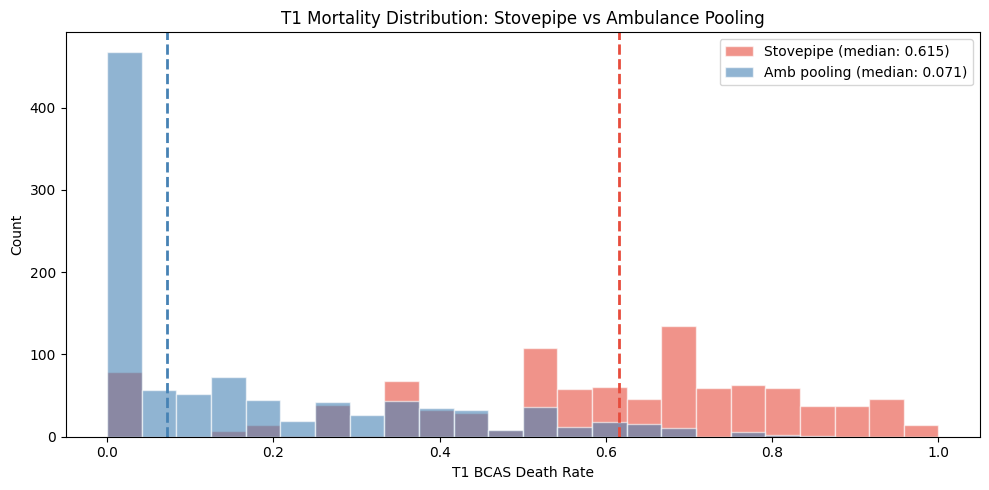

Stovepipe:  mean=0.570, median=0.615, std=0.250
Pooling:    mean=0.157, median=0.071, std=0.199


In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

bins = np.linspace(0, 1, 25)
ax.hist(merged["mort_base"], bins=bins, alpha=0.6, color="#e74c3c", edgecolor="white", label=f"Stovepipe (median: {merged['mort_base'].median():.3f})")
ax.hist(merged["mort_pool"], bins=bins, alpha=0.6, color="steelblue", edgecolor="white", label=f"Amb pooling (median: {merged['mort_pool'].median():.3f})")
ax.axvline(merged["mort_base"].median(), color="#e74c3c", linewidth=2, linestyle="--")
ax.axvline(merged["mort_pool"].median(), color="steelblue", linewidth=2, linestyle="--")
ax.set_xlabel("T1 BCAS Death Rate")
ax.set_ylabel("Count")
ax.set_title("T1 Mortality Distribution: Stovepipe vs Ambulance Pooling")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Stovepipe:  mean={merged['mort_base'].mean():.3f}, median={merged['mort_base'].median():.3f}, std={merged['mort_base'].std():.3f}")
print(f"Pooling:    mean={merged['mort_pool'].mean():.3f}, median={merged['mort_pool'].median():.3f}, std={merged['mort_pool'].std():.3f}")

## Same plots, filtered to bcas_rate ≥ 0.02 (stressed system only)

Stressed scenarios (bcas >= 0.02): 834 / 1000


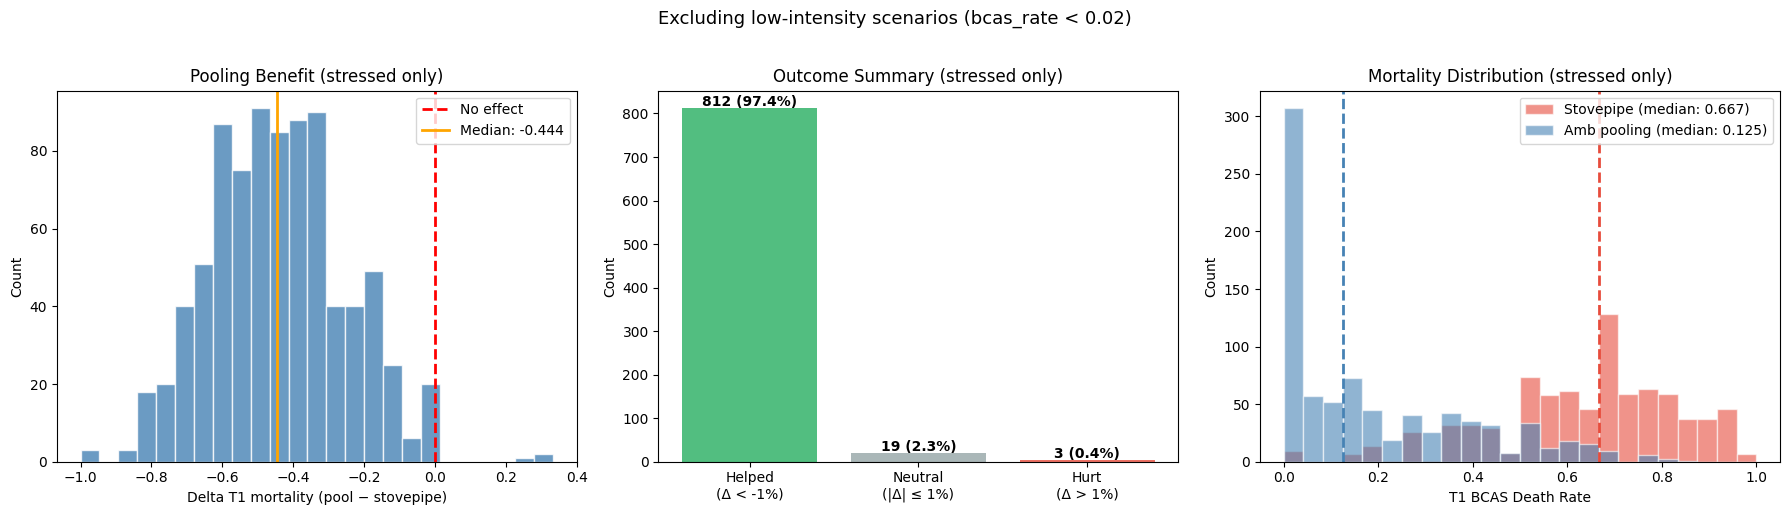

Stovepipe:  mean=0.631, median=0.667
Pooling:    mean=0.185, median=0.125
Delta:      mean=-0.445, median=-0.444


In [4]:
stressed = merged[merged["bcas_rate"] >= 0.02]
print(f"Stressed scenarios (bcas >= 0.02): {len(stressed)} / {len(merged)}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram of delta
axes[0].hist(stressed["delta"], bins=25, color="steelblue", alpha=0.8, edgecolor="white")
axes[0].axvline(0, color="red", linewidth=2, linestyle="--", label="No effect")
axes[0].axvline(stressed["delta"].median(), color="orange", linewidth=2, linestyle="-", label=f"Median: {stressed['delta'].median():.3f}")
axes[0].set_xlabel("Delta T1 mortality (pool − stovepipe)")
axes[0].set_ylabel("Count")
axes[0].set_title("Pooling Benefit (stressed only)")
axes[0].legend()

# Bar chart
n_helped = (stressed["delta"] < -0.01).sum()
n_neutral = ((stressed["delta"] >= -0.01) & (stressed["delta"] <= 0.01)).sum()
n_hurt = (stressed["delta"] > 0.01).sum()
bars = axes[1].bar(["Helped\n(Δ < -1%)", "Neutral\n(|Δ| ≤ 1%)", "Hurt\n(Δ > 1%)"],
                    [n_helped, n_neutral, n_hurt],
                    color=["#27ae60", "#95a5a6", "#e74c3c"], alpha=0.8)
for bar, val in zip(bars, [n_helped, n_neutral, n_hurt]):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f"{val} ({val/len(stressed):.1%})", ha="center", fontweight="bold")
axes[1].set_ylabel("Count")
axes[1].set_title("Outcome Summary (stressed only)")

# Overlapping mortality distributions
bins = np.linspace(0, 1, 25)
axes[2].hist(stressed["mort_base"], bins=bins, alpha=0.6, color="#e74c3c", edgecolor="white",
             label=f"Stovepipe (median: {stressed['mort_base'].median():.3f})")
axes[2].hist(stressed["mort_pool"], bins=bins, alpha=0.6, color="steelblue", edgecolor="white",
             label=f"Amb pooling (median: {stressed['mort_pool'].median():.3f})")
axes[2].axvline(stressed["mort_base"].median(), color="#e74c3c", linewidth=2, linestyle="--")
axes[2].axvline(stressed["mort_pool"].median(), color="steelblue", linewidth=2, linestyle="--")
axes[2].set_xlabel("T1 BCAS Death Rate")
axes[2].set_ylabel("Count")
axes[2].set_title("Mortality Distribution (stressed only)")
axes[2].legend()

plt.suptitle("Excluding low-intensity scenarios (bcas_rate < 0.02)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"Stovepipe:  mean={stressed['mort_base'].mean():.3f}, median={stressed['mort_base'].median():.3f}")
print(f"Pooling:    mean={stressed['mort_pool'].mean():.3f}, median={stressed['mort_pool'].median():.3f}")
print(f"Delta:      mean={stressed['delta'].mean():.3f}, median={stressed['delta'].median():.3f}")

## PRIM — Where does pooling fail to help?

Find the ~10% of scenarios where pooling reduced mortality by less than 10% (or made it worse).

Cases of interest: 103 / 1000 (10.3%)

Selected box:
coverage     0.330097
density      0.629630
id          39.000000
k           34.000000
mass         0.054000
mean         0.629630
n           54.000000
res_dim      3.000000
Name: 39, dtype: float64

                       box 39                                   
                          min        max  qp value      qp value
bcas_rate            0.010323   0.019765       NaN  3.191241e-13
waves_per_day        1.500000   4.500000  0.143733  2.348242e-01
ccp_r1_same_bn_min  11.500000  17.500000  0.255021  1.305361e-01


[None]

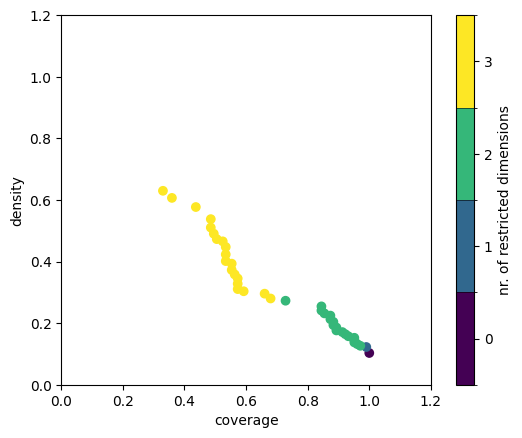

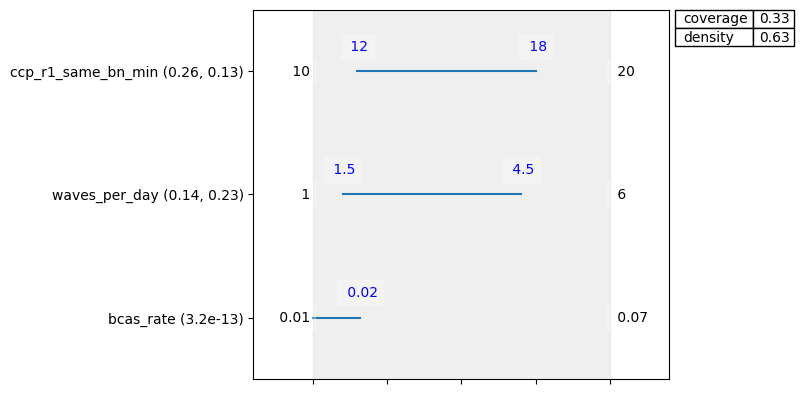

In [5]:
x = merged[UNCERTAINTIES].astype(float)
y = merged["delta"].values > BENEFIT_THRESHOLD

print(f"Cases of interest: {y.sum()} / {len(y)} ({y.mean():.1%})")

p = prim.Prim(x, y, threshold=0.5)
box = p.find_box()
box.show_tradeoff()
print("\nSelected box:")
box.inspect(style="graph")
box.inspect()

## Scenario Pairs for Replay

For each restricted PRIM dimension, find two scenarios that:
- Differ on that dimension (one inside the box, one outside)
- Are as similar as possible on all other dimensions
- Inside = pooling helped a lot, Outside = pooling helped little/not at all

In [6]:
# ── Extract box limits ────────────────────────────────────────────────────────
# box.box_lims[0] is the original range, box.box_lims[-1] is the selected peeling step
# Use box.inspect() output to determine the selected step index
sel_idx = int(box.yi)  # the currently selected peeling step
box_lims = box.box_lims[sel_idx]
orig_lims = box.box_lims[0]

print(f"Selected peeling step: {sel_idx}")
print(f"Box limits:\n{box_lims}\n")

restricted_dims = []
for col in UNCERTAINTIES:
    lo_moved = box_lims[col].iloc[0] > orig_lims[col].iloc[0] + 1e-9
    hi_moved = box_lims[col].iloc[1] < orig_lims[col].iloc[1] - 1e-9
    if lo_moved or hi_moved:
        restricted_dims.append(col)
        print(f"{col}: [{box_lims[col].iloc[0]:.2f}, {box_lims[col].iloc[1]:.2f}]  (original: [{orig_lims[col].iloc[0]:.2f}, {orig_lims[col].iloc[1]:.2f}])")

if not restricted_dims:
    print("No restricted dimensions found — try selecting a different peeling step in the tradeoff plot above.")
    print("You can also manually inspect: box.box_lims[i] for i in range(len(box.box_lims))")

print(f"\nRestricted dimensions: {restricted_dims}")
print(f"Need {len(restricted_dims)} pairs = {len(restricted_dims) * 2} replay scenarios")

TypeError: only 0-dimensional arrays can be converted to Python scalars

In [ ]:
def find_pair(merged_df, vary_dim, box_lims, orig_lims, uncertainties):
    """Find two scenarios that differ on vary_dim but match on others."""
    other_dims = [c for c in uncertainties if c != vary_dim]

    # Inside box on vary_dim AND pooling failed to help
    inside_mask = (
        (merged_df[vary_dim] >= box_lims[vary_dim].iloc[0]) &
        (merged_df[vary_dim] <= box_lims[vary_dim].iloc[1]) &
        (merged_df["delta"] > BENEFIT_THRESHOLD)
    )
    # Outside box on vary_dim AND pooling helped a lot
    outside_mask = (
        ((merged_df[vary_dim] < box_lims[vary_dim].iloc[0]) |
         (merged_df[vary_dim] > box_lims[vary_dim].iloc[1])) &
        (merged_df["delta"] < BENEFIT_THRESHOLD)
    )

    inside = merged_df[inside_mask]
    outside = merged_df[outside_mask]

    if inside.empty or outside.empty:
        print(f"  WARNING: could not find pair for {vary_dim}")
        return None, None

    # Normalize other dims to [0,1] for distance calculation
    ranges = {c: (merged_df[c].max() - merged_df[c].min()) for c in other_dims}

    # Pick the inside scenario where pooling helped least
    inside_row = inside.sort_values("delta", ascending=False).iloc[0]

    # Find closest outside scenario
    def dist_to_inside(row):
        return sum(((row[c] - inside_row[c]) / ranges[c]) ** 2 for c in other_dims if ranges[c] > 0)

    outside = outside.copy()
    outside["_dist"] = outside.apply(dist_to_inside, axis=1)
    outside_row = outside.sort_values("_dist").iloc[0]

    return inside_row, outside_row


# ── Find pairs ────────────────────────────────────────────────────────────────
pairs = {}
for dim in restricted_dims:
    inside_row, outside_row = find_pair(merged, dim, box_lims, orig_lims, UNCERTAINTIES)
    pairs[dim] = (inside_row, outside_row)

    print(f"\n{'='*60}")
    print(f"PAIR for {dim}")
    print(f"{'='*60}")

    if inside_row is None:
        continue

    print(f"\n  POOLING FAILED TO HELP (inside box):")
    for c in UNCERTAINTIES:
        marker = " <<<" if c == dim else ""
        print(f"    {c}: {inside_row[c]}{marker}")
    print(f"    delta: {inside_row['delta']:.4f}  (base: {inside_row['mort_base']:.4f}, pool: {inside_row['mort_pool']:.4f})")

    print(f"\n  POOLING HELPED A LOT (outside box):")
    for c in UNCERTAINTIES:
        marker = " <<<" if c == dim else ""
        print(f"    {c}: {outside_row[c]}{marker}")
    print(f"    delta: {outside_row['delta']:.4f}  (base: {outside_row['mort_base']:.4f}, pool: {outside_row['mort_pool']:.4f})")

## Replay Parameters

Copy these into `runner_multiple.py` or use `replay_run()` with the row indices.

In [ ]:
print("SCENARIO YAML: data/single_run/input/scenarios/scenario_2btg_pooling_limit_baseline_amb.yaml")
print(f"RESULTS CSV:   {paths.MULTI_RUN_OUTPUT / FOLDER_NAME / 'results.csv'}")
print()

for dim, (inside_row, outside_row) in pairs.items():
    if inside_row is None:
        continue
    print(f"\n── {dim} ──")
    print(f"  Pooling HURT  → row_index in base: {inside_row.name}")
    print(f"    replay_run(results_csv, scenario_path, row_index={inside_row.name})")
    print(f"  Pooling HELPED → row_index in base: {outside_row.name}")
    print(f"    replay_run(results_csv, scenario_path, row_index={outside_row.name})")

## Delta vs Each Uncertainty

Red line at zero. If the median never crosses zero for a parameter, that parameter doesn't control *whether* pooling helps — only *how much*.

## PRIM — Where does mortality occur under ambulance pooling?

Using only the pooling (amb=1) runs, find the box where T1 mortality > 0.

Nonzero mortality under amb pooling: 533 / 1000 (53.3%)

Selected box:
coverage      0.196998
density       0.990566
id           24.000000
k           105.000000
mass          0.106000
mean          0.990566
n           106.000000
res_dim       3.000000
Name: 24, dtype: float64

                     box 24                                       
                        min        max      qp value      qp value
waves_per_day      1.000000   1.500000           NaN  1.011915e-12
wave_duration_min  1.000000  58.000000           NaN  4.186765e-01
bcas_rate          0.031505   0.069866  6.637133e-10           NaN


[None]

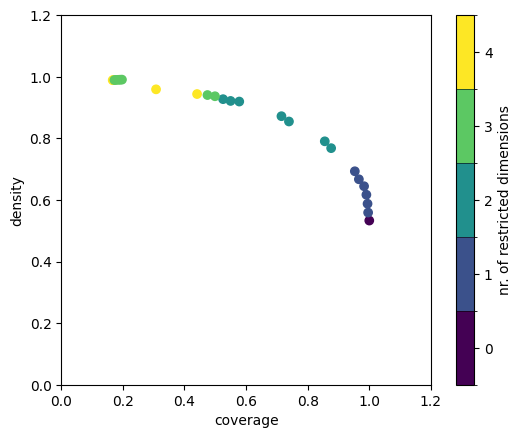

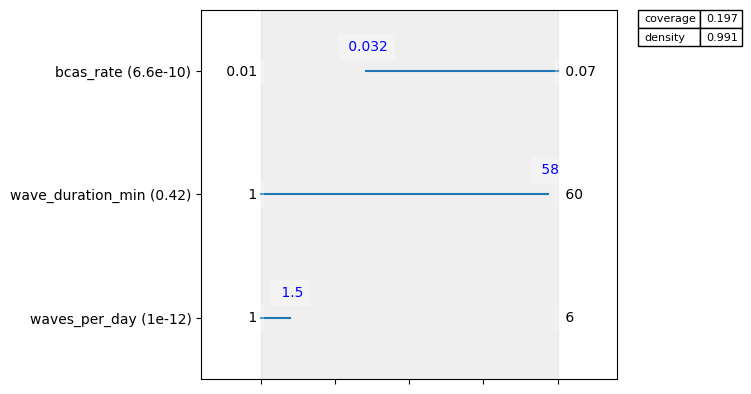

In [7]:
x_pool = pool[UNCERTAINTIES].astype(float)
y_pool_mort = pool[OUTCOME].values > 0

print(f"Nonzero mortality under amb pooling: {y_pool_mort.sum()} / {len(y_pool_mort)} ({y_pool_mort.mean():.1%})")

p_pool = prim.Prim(x_pool, y_pool_mort, threshold=0.5)
box_pool = p_pool.find_box()
box_pool.show_tradeoff()
print("\nSelected box:")
box_pool.inspect(style="graph")
box_pool.inspect()